In [1]:
import requests
import json
import pandas as pd
from requests import Session
from requests.exceptions import ConnectionError, Timeout, TooManyRedirects

url = 'https://pro-api.coinmarketcap.com/v1/cryptocurrency/listings/latest'

parameters = {
  'start':'1',
  'limit':'15',
  'convert':'USD'
}

headers = {
  'Accepts': 'application/json',
  'X-CMC_PRO_API_KEY': 'YOUR_API_HERE',
}

session = Session()
session.headers.update(headers)

try:
  response = session.get(url, params=parameters)
  data = json.loads(response.text)
  print(data)  # to see if you got Bitcoin or error
except (ConnectionError, Timeout, TooManyRedirects) as e:
  print(e)

{'data': [{'id': 1, 'name': 'Bitcoin', 'symbol': 'BTC', 'slug': 'bitcoin', 'infinite_supply': False, 'circulating_supply': 20098843, 'total_supply': 20098843, 'max_supply': 21000000, 'date_added': '2010-07-13T00:00:00.000Z', 'num_market_pairs': 12767, 'cmc_rank': 1, 'last_updated': '2026-10-20T15:24:00.000Z', 'tvl_ratio': None, 'platform': None, 'self_reported_circulating_supply': None, 'self_reported_market_cap': None, 'minted_market_cap': 1654329645218.49, 'quote': {'USD': {'price': 82309.69539980436, 'volume_24h': 25548698464.37748, 'cex_volume_24h': 25510411398.21872, 'dex_volume_24h': 38287066.15875763, 'volume_change_24h': -4.4917, 'percent_change_1h': -0.63331618, 'percent_change_24h': -0.0616283, 'percent_change_7d': -1.58979512, 'percent_change_30d': 1.88233346, 'percent_change_60d': 6.05124593, 'percent_change_90d': 24.69767895, 'market_cap': 1654329645218.49, 'market_cap_dominance': 60.0519, 'fully_diluted_market_cap': 1728503603395.89, 'tvl': None, 'last_updated': '2026-10-

In [2]:
df = pd.json_normalize(data['data'])
df['timestamp'] = pd.to_datetime('now')
df.head()

,id,name,symbol,slug,infinite_supply,circulating_supply,total_supply,max_supply,date_added,num_market_pairs,...,quote.USD.market_cap_dominance,quote.USD.fully_diluted_market_cap,quote.USD.tvl,quote.USD.last_updated,platform.id,platform.slug,platform.name,platform.symbol,platform.token_address,timestamp
0,1,Bitcoin,BTC,bitcoin,False,2.009884e+07,2.009884e+07,2.100000e+07,2010-07-13T00:00:00.000Z,12767,...,60.0519,1.728504e+12,None,2026-10-20T15:24:00.000Z,NaN,NaN,NaN,NaN,NaN,2026-10-20 16:25:49.436196
1,1027,Ethereum,ETH,ethereum,True,1.221513e+08,1.221513e+08,NaN,2015-08-07T00:00:00.000Z,14102,...,10.7704,2.967065e+11,None,2026-10-20T15:24:00.000Z,NaN,NaN,NaN,NaN,NaN,2026-10-20 16:25:49.436196
2,825,Tether USDt,USDT,tether,True,1.831762e+11,1.893155e+11,NaN,2015-02-25T00:00:00.000Z,204783,...,6.6356,1.891084e+11,None,2026-10-20T15:23:00.000Z,1027.0,ethereum,Ethereum,ETH,0xdac17f958d2ee523a2206206994597c13d831ec7,2026-10-20 16:25:49.436196
3,1839,BNB,BNB,bnb,False,1.315120e+08,1.315120e+08,1.315120e+08,2017-07-25T00:00:00.000Z,3514,...,3.4910,9.630383e+10,None,2026-10-20T15:24:00.000Z,NaN,NaN,NaN,NaN,NaN,2026-10-20 16:25:49.436196
4,52,XRP,XRP,xrp,False,6.312967e+10,9.998561e+10,1.000000e+11,2013-08-04T00:00:00.000Z,1891,...,3.0137,1.315111e+11,None,2026-10-20T15:23:00.000Z,NaN,NaN,NaN,NaN,NaN,2026-10-20 16:25:49.436196


In [3]:
def api_runner():
    global df
    try:
        response = session.get(url, params=parameters)
        data = json.loads(response.text)
        df2 = pd.json_normalize(data['data'])
        df2['timestamp'] = pd.to_datetime('now')
        df = pd.concat([df, df2], ignore_index=True)
        print("pull done - rows now:", len(df))
    except (ConnectionError, Timeout, TooManyRedirects) as e:
        print(e)

api_runner()

pull done - rows now: 30


In [4]:
import os
from time import time
from time import sleep

for i in range(4):
    api_runner()
    print('API Runner Completed')
    sleep(60)

pull done - rows now: 45
API Runner Completed
pull done - rows now: 60
API Runner Completed
pull done - rows now: 75
API Runner Completed
pull done - rows now: 90
API Runner Completed


KeyboardInterrupt: 

In [5]:
df

,id,name,symbol,slug,infinite_supply,circulating_supply,total_supply,max_supply,date_added,num_market_pairs,...,quote.USD.market_cap_dominance,quote.USD.fully_diluted_market_cap,quote.USD.tvl,quote.USD.last_updated,platform.id,platform.slug,platform.name,platform.symbol,platform.token_address,timestamp
0,1,Bitcoin,BTC,bitcoin,False,2.009884e+07,2.009884e+07,2.100000e+07,2010-07-13T00:00:00.000Z,12767,...,60.0519,1.728504e+12,None,2026-10-20T15:24:00.000Z,NaN,NaN,NaN,NaN,NaN,2026-10-20 16:25:49.436196
1,1027,Ethereum,ETH,ethereum,True,1.221513e+08,1.221513e+08,NaN,2015-08-07T00:00:00.000Z,14102,...,10.7704,2.967065e+11,None,2026-10-20T15:24:00.000Z,NaN,NaN,NaN,NaN,NaN,2026-10-20 16:25:49.436196
2,825,Tether USDt,USDT,tether,True,1.831762e+11,1.893155e+11,NaN,2015-02-25T00:00:00.000Z,204783,...,6.6356,1.891084e+11,None,2026-10-20T15:23:00.000Z,1027.0,ethereum,Ethereum,ETH,0xdac17f958d2ee523a2206206994597c13d831ec7,2026-10-20 16:25:49.436196
3,1839,BNB,BNB,bnb,False,1.315120e+08,1.315120e+08,1.315120e+08,2017-07-25T00:00:00.000Z,3514,...,3.4910,9.630383e+10,None,2026-10-20T15:24:00.000Z,NaN,NaN,NaN,NaN,NaN,2026-10-20 16:25:49.436196
4,52,XRP,XRP,xrp,False,6.312967e+10,9.998561e+10,1.000000e+11,2013-08-04T00:00:00.000Z,1891,...,3.0137,1.315111e+11,None,2026-10-20T15:23:00.000Z,NaN,NaN,NaN,NaN,NaN,2026-10-20 16:25:49.436196
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
85,74,Dogecoin,DOGE,dogecoin,True,1.564045e+11,1.564045e+11,NaN,2013-12-15T00:00:00.000Z,1538,...,0.4551,1.253767e+10,None,2026-10-20T15:27:00.000Z,NaN,NaN,NaN,NaN,NaN,2026-10-20 16:29:37.658538
86,328,Monero,XMR,monero,True,1.882015e+07,1.882015e+07,NaN,2014-05-21T00:00:00.000Z,379,...,0.4265,1.174185e+10,None,2026-10-20T15:28:00.000Z,NaN,NaN,NaN,NaN,NaN,2026-10-20 16:29:37.658538
87,1975,Chainlink,LINK,chainlink,False,7.481000e+08,1.000000e+09,1.000000e+09,2017-09-20T00:00:00.000Z,2309,...,0.3294,1.212066e+10,None,2026-10-20T15:28:00.000Z,1027.0,ethereum,Ethereum,ETH,0x514910771af9ca656af840dff83e8264ecf986ca,2026-10-20 16:29:37.658538
88,3957,UNUS SED LEO,LEO,unus-sed-leo,False,9.198579e+08,9.852395e+08,NaN,2019-05-21T00:00:00.000Z,70,...,0.3015,8.888893e+09,None,2026-10-20T15:28:00.000Z,1027.0,ethereum,Ethereum,ETH,0x2af5d2ad76741191d15dfe7bf6ac92d4bd912ca3,2026-10-20 16:29:37.658538


In [7]:
pd.set_option('display.float_format', lambda x: '%.5f' % x)
df

,id,name,symbol,slug,infinite_supply,circulating_supply,total_supply,max_supply,date_added,num_market_pairs,...,quote.USD.market_cap_dominance,quote.USD.fully_diluted_market_cap,quote.USD.tvl,quote.USD.last_updated,platform.id,platform.slug,platform.name,platform.symbol,platform.token_address,timestamp
0,1,Bitcoin,BTC,bitcoin,False,20098843.00000,20098843.00000,21000000.00000,2010-07-13T00:00:00.000Z,12767,...,60.05190,1728503603395.88989,None,2026-10-20T15:24:00.000Z,NaN,NaN,NaN,NaN,NaN,2026-10-20 16:25:49.436196
1,1027,Ethereum,ETH,ethereum,True,122151332.39495,122151332.39495,NaN,2015-08-07T00:00:00.000Z,14102,...,10.77040,296706529598.22998,None,2026-10-20T15:24:00.000Z,NaN,NaN,NaN,NaN,NaN,2026-10-20 16:25:49.436196
2,825,Tether USDt,USDT,tether,True,183176219727.94333,189315488419.19775,NaN,2015-02-25T00:00:00.000Z,204783,...,6.63560,189108399972.14999,None,2026-10-20T15:23:00.000Z,1027.00000,ethereum,Ethereum,ETH,0xdac17f958d2ee523a2206206994597c13d831ec7,2026-10-20 16:25:49.436196
3,1839,BNB,BNB,bnb,False,131512016.92000,131512016.92000,131512018.56000,2017-07-25T00:00:00.000Z,3514,...,3.49100,96303831072.97000,None,2026-10-20T15:24:00.000Z,NaN,NaN,NaN,NaN,NaN,2026-10-20 16:25:49.436196
4,52,XRP,XRP,xrp,False,63129671205.00000,99985607990.00000,100000000000.00000,2013-08-04T00:00:00.000Z,1891,...,3.01370,131511133833.37000,None,2026-10-20T15:23:00.000Z,NaN,NaN,NaN,NaN,NaN,2026-10-20 16:25:49.436196
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
85,74,Dogecoin,DOGE,dogecoin,True,156404536383.70520,156404536383.70520,NaN,2013-12-15T00:00:00.000Z,1538,...,0.45510,12537669640.71000,None,2026-10-20T15:27:00.000Z,NaN,NaN,NaN,NaN,NaN,2026-10-20 16:29:37.658538
86,328,Monero,XMR,monero,True,18820148.89809,18820148.89809,NaN,2014-05-21T00:00:00.000Z,379,...,0.42650,11741847800.17000,None,2026-10-20T15:28:00.000Z,NaN,NaN,NaN,NaN,NaN,2026-10-20 16:29:37.658538
87,1975,Chainlink,LINK,chainlink,False,748099970.42488,1000000000.00000,1000000000.00000,2017-09-20T00:00:00.000Z,2309,...,0.32940,12120657452.82000,None,2026-10-20T15:28:00.000Z,1027.00000,ethereum,Ethereum,ETH,0x514910771af9ca656af840dff83e8264ecf986ca,2026-10-20 16:29:37.658538
88,3957,UNUS SED LEO,LEO,unus-sed-leo,False,919857851.90000,985239504.00000,NaN,2019-05-21T00:00:00.000Z,70,...,0.30150,8888893337.50000,None,2026-10-20T15:28:00.000Z,1027.00000,ethereum,Ethereum,ETH,0x2af5d2ad76741191d15dfe7bf6ac92d4bd912ca3,2026-10-20 16:29:37.658538


In [8]:
print(df.columns.tolist())

['id', 'name', 'symbol', 'slug', 'infinite_supply', 'circulating_supply', 'total_supply', 'max_supply', 'date_added', 'num_market_pairs', 'cmc_rank', 'last_updated', 'tvl_ratio', 'platform', 'self_reported_circulating_supply', 'self_reported_market_cap', 'minted_market_cap', 'tags', 'quote.USD.price', 'quote.USD.volume_24h', 'quote.USD.cex_volume_24h', 'quote.USD.dex_volume_24h', 'quote.USD.volume_change_24h', 'quote.USD.percent_change_1h', 'quote.USD.percent_change_24h', 'quote.USD.percent_change_7d', 'quote.USD.percent_change_30d', 'quote.USD.percent_change_60d', 'quote.USD.percent_change_90d', 'quote.USD.market_cap', 'quote.USD.market_cap_dominance', 'quote.USD.fully_diluted_market_cap', 'quote.USD.tvl', 'quote.USD.last_updated', 'platform.id', 'platform.slug', 'platform.name', 'platform.symbol', 'platform.token_address', 'timestamp']


In [9]:
# 1. See if columns exist
df.filter(like='quote.USD').columns

# 2. Show only those columns like Alex
df[['name','quote.USD.price','quote.USD.percent_change_1h','quote.USD.percent_change_24h','quote.USD.percent_change_7d']]

,name,quote.USD.price,quote.USD.percent_change_1h,quote.USD.percent_change_24h,quote.USD.percent_change_7d
0,Bitcoin,82309.69540,-0.63332,-0.06163,-1.58980
1,Ethereum,2429.00772,-1.01655,0.52807,-3.61426
2,Tether USDt,0.99891,0.00728,-0.00007,0.01108
3,BNB,732.28160,-0.76707,0.75047,-1.64835
4,XRP,1.31511,-1.07082,0.65412,-4.14261
...,...,...,...,...,...
85,Dogecoin,0.08016,-1.42721,0.69334,-5.03751
86,Monero,623.89771,2.38004,3.12148,17.78065
87,Chainlink,12.12066,-1.89371,0.47050,-6.46387
88,UNUS SED LEO,9.02206,0.00272,-0.14247,1.34746


In [14]:

df3 = df.groupby('name', sort=False)[['quote.USD.percent_change_1h','quote.USD.percent_change_24h','quote.USD.percent_change_7d','quote.USD.percent_change_30d','quote.USD.percent_change_60d','quote.USD.percent_change_90d']].mean()

df3

,quote.USD.percent_change_1h,quote.USD.percent_change_24h,quote.USD.percent_change_7d,quote.USD.percent_change_30d,quote.USD.percent_change_60d,quote.USD.percent_change_90d
name,,,,,,
Bitcoin,-0.60473,-0.02058,-1.44821,1.99708,6.00816,24.70511
Ethereum,-1.04398,0.52235,-3.56037,-6.48429,1.17838,24.69283
Tether USDt,-0.00070,-0.00114,0.00238,-0.08644,-0.08804,-0.06738
BNB,-0.74960,0.66033,-1.68249,-3.09949,7.62167,27.83087
XRP,-1.15438,0.53688,-4.26768,-5.06240,-6.96331,14.07246
USDC,-0.00563,-0.00370,-0.00774,-0.01283,-0.02038,-0.01576
Solana,-2.09114,0.11206,-2.40093,-2.93823,14.58911,33.78977
TRON,-0.10319,-0.25504,1.25233,-3.92968,-2.68451,0.76698
Hyperliquid,-1.56224,0.68785,-1.65811,-12.68673,3.91340,36.12159


In [15]:
df.to_csv('crypto_120_rows_backup.csv', index=False)
df.to_csv('API.csv', index=False)
print(f"Saved! {len(df)} rows saved in 2 places")

Saved! 90 rows saved in 2 places


In [16]:
df3.to_csv('crypto_mean_90days.csv')
print("df3 saved!")

df3 saved!


In [17]:
df4 = df3.stack()
df4

name                                 
Bitcoin  quote.USD.percent_change_1h    -0.60473
         quote.USD.percent_change_24h   -0.02058
         quote.USD.percent_change_7d    -1.44821
         quote.USD.percent_change_30d    1.99708
         quote.USD.percent_change_60d    6.00816
                                          ...   
Cardano  quote.USD.percent_change_24h    0.72571
         quote.USD.percent_change_7d    -6.50081
         quote.USD.percent_change_30d   -1.14524
         quote.USD.percent_change_60d    0.97256
         quote.USD.percent_change_90d   24.17863
Length: 90, dtype: float64

In [18]:
type(df4)

pandas.Series

In [19]:
df5 = df4.to_frame(name='values')
df5

values
name                                         
Bitcoin quote.USD.percent_change_1h  -0.60473
        quote.USD.percent_change_24h -0.02058
        quote.USD.percent_change_7d  -1.44821
        quote.USD.percent_change_30d  1.99708
        quote.USD.percent_change_60d  6.00816
...                                       ...
Cardano quote.USD.percent_change_24h  0.72571
        quote.USD.percent_change_7d  -6.50081
        quote.USD.percent_change_30d -1.14524
        quote.USD.percent_change_60d  0.97256
        quote.USD.percent_change_90d 24.17863

[90 rows x 1 columns]

In [20]:
type(df5)

pandas.DataFrame

In [21]:
df5.count()

values    90
dtype: int64

In [24]:
index = pd.Index(range(90))
df6 = df5.reset_index()
df6


,name,level_1,values
0,Bitcoin,quote.USD.percent_change_1h,-0.60473
1,Bitcoin,quote.USD.percent_change_24h,-0.02058
2,Bitcoin,quote.USD.percent_change_7d,-1.44821
3,Bitcoin,quote.USD.percent_change_30d,1.99708
4,Bitcoin,quote.USD.percent_change_60d,6.00816
...,...,...,...
85,Cardano,quote.USD.percent_change_24h,0.72571
86,Cardano,quote.USD.percent_change_7d,-6.50081
87,Cardano,quote.USD.percent_change_30d,-1.14524
88,Cardano,quote.USD.percent_change_60d,0.97256


In [26]:
df7 = df6.rename(columns={'level_1': 'percent_change'})
df7

,name,percent_change,values
0,Bitcoin,quote.USD.percent_change_1h,-0.60473
1,Bitcoin,quote.USD.percent_change_24h,-0.02058
2,Bitcoin,quote.USD.percent_change_7d,-1.44821
3,Bitcoin,quote.USD.percent_change_30d,1.99708
4,Bitcoin,quote.USD.percent_change_60d,6.00816
...,...,...,...
85,Cardano,quote.USD.percent_change_24h,0.72571
86,Cardano,quote.USD.percent_change_7d,-6.50081
87,Cardano,quote.USD.percent_change_30d,-1.14524
88,Cardano,quote.USD.percent_change_60d,0.97256


In [39]:
df7['percent_change'] = df7['percent_change'].replace(['quote.USD.percent_change_24h','quote.USD.percent_change_7d','quote.USD.percent_change_30d','quote.USD.percent_change_60d','quote.USD.percent_change_90d'],['24h','7d','30d','60d','90d'])
df7

,name,percent_change,values
0,Bitcoin,1h,-0.60473
1,Bitcoin,24h,-0.02058
2,Bitcoin,7d,-1.44821
3,Bitcoin,30d,1.99708
4,Bitcoin,60d,6.00816
...,...,...,...
85,Cardano,24h,0.72571
86,Cardano,7d,-6.50081
87,Cardano,30d,-1.14524
88,Cardano,60d,0.97256


In [40]:
import seaborn as sns
import matplotlib.pyplot as plt

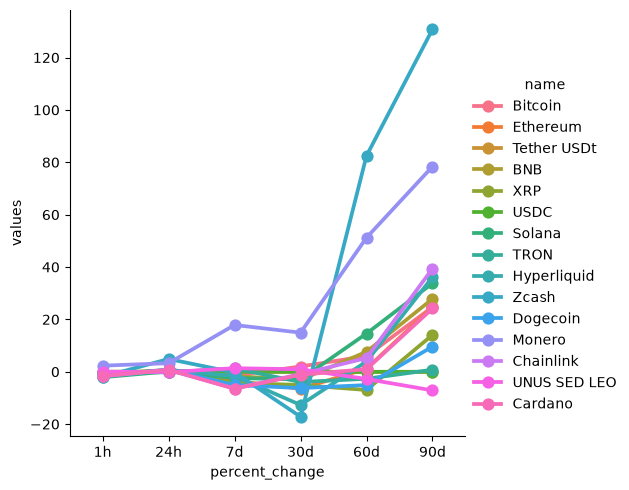

In [41]:
sns.catplot(x='percent_change', y='values', hue='name', data=df7, kind='point')

In [45]:
df10 = df[['name','quote.USD.price','timestamp']]
df10 = df10.query("name == 'Bitcoin'")
df10

,name,quote.USD.price,timestamp
0,Bitcoin,82309.69540,2026-10-20 16:25:49.436196
15,Bitcoin,82381.45096,2026-10-20 16:26:14.904814
30,Bitcoin,82381.45096,2026-10-20 16:26:34.999653
45,Bitcoin,82407.20041,2026-10-20 16:27:36.112202
60,Bitcoin,82335.81582,2026-10-20 16:28:37.141067
75,Bitcoin,82341.20919,2026-10-20 16:29:37.658538


<Axes: xlabel='timestamp', ylabel='quote.USD.price'>

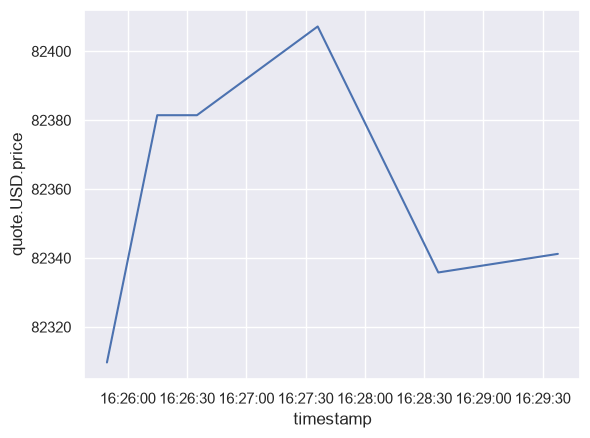

In [47]:
sns.set_theme(style="darkgrid")
sns.lineplot(x='timestamp', y='quote.USD.price', data = df10)

In [54]:
import os
print(os.getcwd())

C:\Users\HP


In [55]:
import os
os.startfile(os.getcwd())